# Задание 1 (5 балла)

Имплементируйте алгоритм Леска (описание есть в семинаре) и оцените качество его работы на датасете `data/corpus_wsd_50k.txt`

В качестве метрики близости вы должны попробовать два подхода:

1) Jaccard score на множествах слов (определений и контекста)
2) Cosine distance на эмбедингах sentence_transformers

В качестве метрики используйте accuracy (% правильных ответов). Предсказывайте только многозначные слова в датасете

Контекст вы можете определить самостоятельно (окно вокруг целевого слова или все предложение). Также можете поэкспериментировать с предобработкой для обоих методов.

Алгоритм у него достаточно простой: 1) для неоднозначного слова находятся определения всех его значений; 2) выбирается контекст, в котором встретилось неоднозначное слово - обычно это какое-то окно вокруг слова (5 слов слева + 5 слов справа); 3) контекст сравнивается с каждым из определений и выбирается значение с наибольшей близостью к контексту.

In [ ]:
!wget -q https://github.com/mannefedov/compling_nlp_hse_course/raw/master/data/corpus_wsd_50k.txt.zip
!unzip -o -q corpus_wsd_50k.txt.zip -d data
!pip install -q spacy
!python -m spacy download en_core_web_sm

In [86]:
import pandas as pd
import nltk
import spacy
from tqdm.auto import tqdm
from nltk.corpus import stopwords, wordnet as wn
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

nltk.download('wordnet')
nltk.download('stopwords')

tqdm.pandas()

stop_words = set(stopwords.words('english'))
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

model = SentenceTransformer('sentence-transformers/all-mpnet-base-v2')
embed = model.encode

### Корпус + делаю датасет для оценки

In [120]:
with open('data/corpus_wsd_50k.txt', encoding='utf-8') as f:
    corpus = f.read().split('\n\n')

corpus_wsd = []
for sent in corpus:
    corpus_wsd.append([s.split('\t') for s in sent.split('\n') if s.strip()])

In [121]:
def get_all(sent, i, left=5, right=5, whole_sentence=False):
    lemma = sent[i][1]
    all_def = {s.name(): s.definition() for s in wn.synsets(lemma)}
    if whole_sentence:
        tokens = sent
    else:
        before = sent[max(0, i - left): i]
        after = sent[i + 1: i + 1 + right]
        tokens = before + after
    context = ' '.join(t[1] for t in tokens)
    true_syn = wn.lemma_from_key(sent[i][0]).synset().name()
    return all_def, context, true_syn

In [122]:
rows = []
for sent_id, sent in enumerate(tqdm(corpus_wsd[:10])):
    for i, tok in enumerate(sent):
        if tok[0]:
            all_def, context, true_syn = get_all(sent, i)
            rows.append({
                'lemma': tok[1],
                'context': context,
                'definitions': all_def,
                'true_synset': true_syn,
            })

dataset = pd.DataFrame(rows) # новый датасет для оценки

100%|██████████| 10/10 [00:00<00:00, 783.66it/s]


### Препроцессинг

In [123]:
# препроцессинг
def preprocess(text, lemmatization=True, lower=True, stopwords_del=True, punct_del=True):
    if lower:
        text = text.lower()
    doc = nlp(text)
    if lemmatization:
        tokens = [t.lemma_.lower() for t in doc]
    else:
        tokens = [t.text for t in doc]
    if punct_del:
        tokens = [w for w in tokens if any(ch.isalnum() for ch in w)]
    if stopwords_del:
        tokens = [w for w in tokens if w not in stop_words]
    return tokens

# жаккар
def jaccard (a, b):
    a, b = set(a), set(b)
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)

# косинусная близость
def vectors (a, b):
  a = embed(a)
  b = embed(b)
  return cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0][0]

# косинусная близость принимает строку, жаккар -- множества
def prepare(text, use_preprocess=True, as_text=False):
    if use_preprocess:
        tokens = preprocess(text)
        return ' '.join(tokens) if as_text else tokens
    return text if as_text else text.split()

# предсказание
def prediction(row, metric='jaccard', use_preprocess=True):
    if metric == 'jaccard':
        sim, as_text = jaccard, False
    elif metric == 'vectors':
        sim, as_text = vectors, True

    context = prepare(row['context'], use_preprocess, as_text)
    values = {syn: sim(context, prepare(text, use_preprocess, as_text)) for syn, text in row['definitions'].items()}

    return max(values, key=values.get, default=None)

### Предсказание и оценка

In [124]:
dataset['pred'] = dataset.progress_apply(prediction, axis=1, metric='vectors')

  1%|▏         | 1/67 [00:02<02:55,  2.67s/it]


KeyboardInterrupt: 

In [114]:
accuracy = accuracy_score(dataset['true_synset'], dataset['pred'])
accuracy

0.34328358208955223

### Играюсь с параметрами

In [128]:
contexts = {
    'window 5+5':   dict(left=5, right=5),
    'sentence':     dict(whole_sentence=True),
}
metrics = ['jaccard', 'vectors']
preprocess_modes = [True, False]

N = 10
sample = corpus_wsd[:N]

In [129]:
results = []

for ctx_name, ctx in contexts.items():
    rows = []
    for sent in sample:
        for i, tok in enumerate(sent):
            if tok[0]:
                all_def, context, true_syn = get_all(sent, i, **ctx)
                if len(all_def) > 1:
                    rows.append({'context': context, 'definitions': all_def, 'true_synset': true_syn})
    dataset = pd.DataFrame(rows)

    for metric in metrics:
        for use_prep in preprocess_modes:
            pred = dataset.progress_apply(prediction, axis=1, metric=metric, use_preprocess=use_prep)
            acc = accuracy_score(dataset['true_synset'], pred)
            results.append((ctx_name, metric, use_prep, acc))

results_df = pd.DataFrame(results, columns=['context', 'metric', 'preprocess', 'accuracy'])
results_df

100%|██████████| 63/63 [02:08<00:00,  2.03s/it]


,context,metric,preprocess,accuracy
0,window 5+5,jaccard,True,0.365079
1,window 5+5,jaccard,False,0.333333
2,window 5+5,vectors,True,0.301587
3,window 5+5,vectors,False,0.333333
4,sentence,jaccard,True,0.349206
5,sentence,jaccard,False,0.317460
6,sentence,vectors,True,0.380952
7,sentence,vectors,False,0.349206


In [130]:
results_df.pivot_table(index=['metric', 'preprocess'], columns='context', values='accuracy').round(3)

context             sentence  window 5+5
metric  preprocess                      
jaccard False          0.317       0.333
        True           0.349       0.365
vectors False          0.349       0.333
        True           0.381       0.302

Качество примерно одного порядка, но лучше работает либо векторная близость с предобработкой (удивительно! динамические эмбеддинги не слишком должны дружить с лемматизацией и удалением стоп-слов) и контекстом = предложение (это как раз ожидаемо), либо (похуже) Жаккар с предобработкой и окном 5 слов слева + 5 слов справа.

# Задание 2 (5 балла)
Попробуйте разные алгоритмы кластеризации на датасете - `https://github.com/nlpub/russe-wsi-kit/blob/initial/data/main/wiki-wiki/train.csv`

Используйте код из семинара как основу. Используйте ARI как метрику качества.

Попробуйте все 4 алгоритма кластеризации, про которые говорилось на семинаре. Для каждого из алгоритмов попробуйте настраивать гиперпараметры (посмотрите их в документации). Прогоните как минимум 5 экспериментов (не обязательно успешных) с разными параметрами на каждый алгоритме кластеризации и оцените: качество кластеризации, скорость работы, интуитивность параметров.

Помимо этого также выберите 1 дополнительный алгоритм кластеризации отсюда - https://scikit-learn.org/stable/modules/clustering.html , опишите своими словами принцип его работы  и проделайте аналогичные эксперименты.

In [169]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN, AffinityPropagation, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2') # русский язык в задании, меняют модель
embed = model.encode

In [ ]:
!pip install umap-learn

In [134]:
url = 'https://raw.githubusercontent.com/nlpub/russe-wsi-kit/initial/data/main/wiki-wiki/train.csv'
df = pd.read_csv(url, sep='\t')
grouped_df = df.groupby('word')

embeddings = {}
pbar = tqdm(grouped_df)
for key, group in pbar:
    embeddings[key] = model.encode(list(group['context']), normalize_embeddings=True, show_progress_bar=False)

100%|██████████| 4/4 [02:43<00:00, 40.83s/it]


Как выглядят данные

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


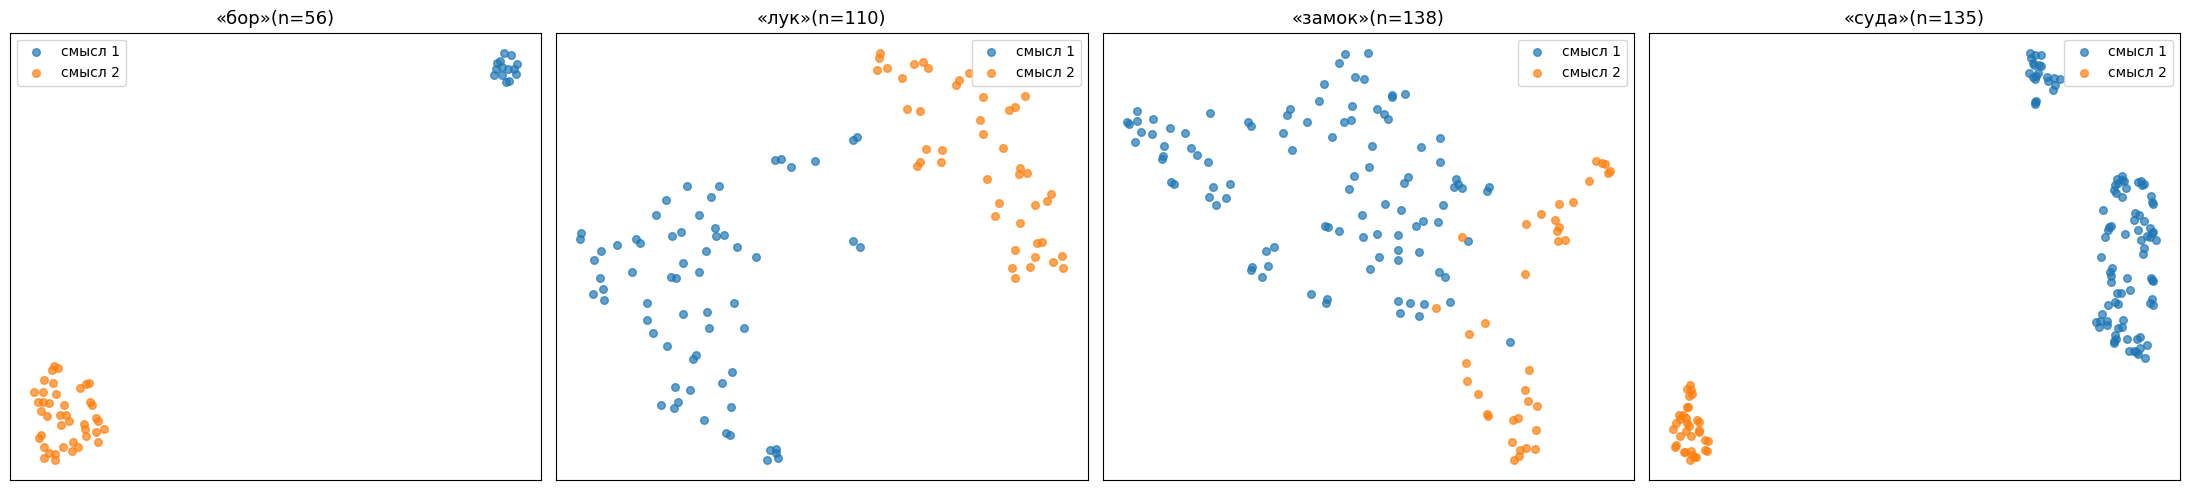

In [196]:
import umap
import matplotlib.pyplot as plt

words = ['бор', 'лук', 'замок', 'суда']

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, word in zip(axes, words):
    group = grouped_df.get_group(word)
    X = embeddings[word]
    y_true = group['gold_sense_id'].values

    X_2d = umap.UMAP(
        n_neighbors=15, min_dist=0.1, random_state=42
    ).fit_transform(X)

    senses = sorted(set(y_true))
    palette = plt.cm.tab10(range(len(senses)))

    for sense, color in zip(senses, palette):
        mask = y_true == sense
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   color=color, alpha=0.7, s=30,
                   label=f'смысл {sense}')

    ax.set_title(f'«{word}»(n={len(X)})', fontsize=13)
    ax.legend(fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

In [157]:
def evaluate(cluster, name):
    start = time.time()
    ARI = []
    for key, group in grouped_df:
        labels = cluster.fit_predict(embeddings[key])
        ARI.append(adjusted_rand_score(group['gold_sense_id'], labels))
    ari = np.mean(ARI)
    print(name, '| ARI:', round(ari, 3), '| время:', round(time.time() - start, 2))
    return ari

### DBSCAN

`eps` -- радиус вокруг точки (евклидово расстояние). Для нормированных эмбеддингов (как у нас) имеет нормальный рэндж значений, для ненормированных должен иметь больший разборс.



Угадать 0.9 без эксперимента почти невозможно. А еще всего 3 нормальных значения на сетке из 19 -- параметр очень чувствительный.

eps=0.1 | ARI: 0.0 | время: 0.17
eps=0.2 | ARI: -0.005 | время: 0.09
eps=0.3 | ARI: -0.039 | время: 0.1
eps=0.4 | ARI: -0.015 | время: 0.08
eps=0.5 | ARI: 0.005 | время: 0.03
eps=0.6 | ARI: -0.039 | время: 0.04
eps=0.7 | ARI: 0.218 | время: 0.14
eps=0.8 | ARI: 0.267 | время: 0.09
eps=0.9 | ARI: 0.41 | время: 0.07
eps=1.0 | ARI: -0.013 | время: 0.08
eps=1.1 | ARI: -0.003 | время: 0.1
eps=1.2 | ARI: 0.0 | время: 0.1
eps=1.3 | ARI: 0.0 | время: 0.13
eps=1.4 | ARI: 0.0 | время: 0.1
eps=1.5 | ARI: 0.0 | время: 0.13
eps=1.6 | ARI: 0.0 | время: 0.1
eps=1.7 | ARI: 0.0 | время: 0.03
eps=1.8 | ARI: 0.0 | время: 0.1
eps=1.9 | ARI: 0.0 | время: 0.16
Лучшее: eps=0.9, ARI=0.410, кластеров (бор, лук, замок, суда)=[2, 1, 1, 2]


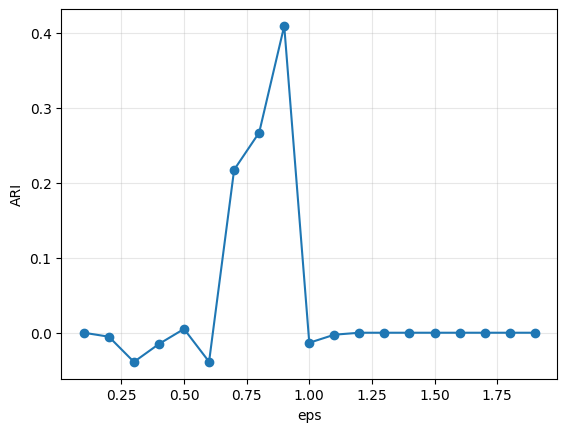

In [191]:
eps_values = np.arange(0.1, 2.0, 0.1)
aris, ks = [], []
for e in eps_values:
    aris.append(evaluate(DBSCAN(eps=e), f'eps={e:.1f}'))
    ks.append([len(set(DBSCAN(eps=e).fit_predict(embeddings[w])) - {-1}) for w in embeddings])

best_i = int(np.argmax(aris))
print(f'Лучшее: eps={eps_values[best_i]:.1f}, ARI={max(aris):.3f}, кластеров (бор, лук, замок, суда)={ks[best_i]}')

plt.plot(eps_values, aris, 'o-')
plt.xlabel('eps')
plt.ylabel('ARI')
plt.grid(alpha=0.3)
plt.show()

### Affinity Propagation

`damping` -- коэффициент затухания, по сути влияет на сходимость -- при большом сходится медленнее, но устойчивее.

По графику ниже видно, что лучше всего чем ближе к 1 (при этом медленнее! аж 0.47 против ~0.1). Так что дальше посмотрим только на `preference`.

damping=0.50 | ARI: 0.08 | время: 0.4
damping=0.53 | ARI: 0.08 | время: 0.52
damping=0.55 | ARI: 0.08 | время: 0.41
damping=0.58 | ARI: 0.08 | время: 0.49
damping=0.60 | ARI: 0.08 | время: 0.4
damping=0.63 | ARI: 0.08 | время: 0.56
damping=0.65 | ARI: 0.08 | время: 0.53
damping=0.68 | ARI: 0.08 | время: 0.4
damping=0.70 | ARI: 0.08 | время: 0.38
damping=0.73 | ARI: 0.08 | время: 0.3
damping=0.75 | ARI: 0.08 | время: 0.25
damping=0.78 | ARI: 0.079 | время: 0.39
damping=0.80 | ARI: 0.08 | время: 0.21
damping=0.83 | ARI: 0.08 | время: 0.34
damping=0.85 | ARI: 0.08 | время: 0.39
damping=0.88 | ARI: 0.076 | время: 0.43
damping=0.90 | ARI: 0.076 | время: 0.37
damping=0.93 | ARI: 0.077 | время: 0.29
damping=0.95 | ARI: 0.083 | время: 0.43
damping=0.98 | ARI: 0.098 | время: 0.93


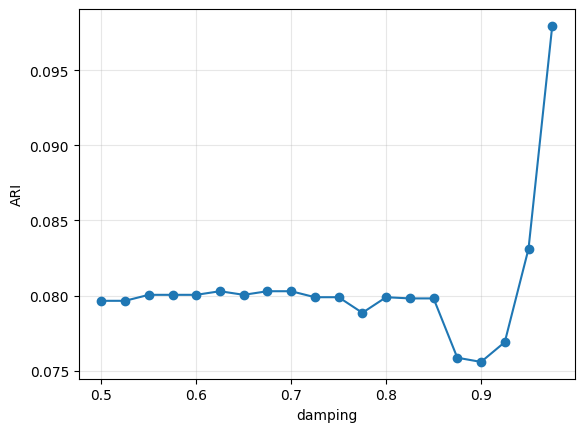

In [188]:
dampings = np.arange(0.5, 1.0, 0.025)
aris = [evaluate(AffinityPropagation(damping=d), f'damping={d:.2f}') for d in dampings]

plt.plot(dampings, aris, 'o-')
plt.xlabel('damping')
plt.ylabel('ARI')
plt.grid(alpha=0.3)
plt.show()

`Preference` -- планка, которую должна преодолеть точка, чтобы стать центром. больше `preference` -- больше кластеров.

График ниже показывает, что оптимальное значение лежит где-то в районе 9.

In [185]:
preferences = range(-20, 0)
aris, ks = [], []
for p in preferences:
    aris.append(evaluate(AffinityPropagation(preference=p), f'preference={p}'))
    ks.append([len(set(AffinityPropagation(preference=p).fit_predict(embeddings[w])) - {-1}) for w in embeddings])

best_i = int(np.argmax(aris))
print(f'Лучшее: preference={list(preferences)[best_i]}, ARI={max(aris):.3f}, кластеров (бор, лук, замок, суда)={ks[best_i]}')

preference=-20 | ARI: 0.149 | время: 0.26


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:140: ConvergenceWarning: Affinity propagation did not converge, this model may return degenerate cluster centers and labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:140: ConvergenceWarning: Affinity propagation did not converge, this model may return degenerate cluster centers and labels.
  warnings.warn(


preference=-19 | ARI: 0.153 | время: 0.4


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:140: ConvergenceWarning: Affinity propagation did not converge, this model may return degenerate cluster centers and labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:162: ConvergenceWarning: Affinity propagation did not converge and this model will not have any cluster centers.
  warnings.warn(


preference=-18 | ARI: 0.355 | время: 0.35
preference=-17 | ARI: 0.364 | время: 0.33


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:140: ConvergenceWarning: Affinity propagation did not converge, this model may return degenerate cluster centers and labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:140: ConvergenceWarning: Affinity propagation did not converge, this model may return degenerate cluster centers and labels.
  warnings.warn(


preference=-16 | ARI: 0.138 | время: 0.35
preference=-15 | ARI: 0.316 | время: 0.32
preference=-14 | ARI: 0.156 | время: 0.14


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_affinity_propagation.py:140: ConvergenceWarning: Affinity propagation did not converge, this model may return degenerate cluster centers and labels.
  warnings.warn(


preference=-13 | ARI: 0.362 | время: 0.09
preference=-12 | ARI: 0.338 | время: 0.26
preference=-11 | ARI: 0.3 | время: 0.26
preference=-10 | ARI: 0.338 | время: 0.18
preference=-9 | ARI: 0.554 | время: 0.19
preference=-8 | ARI: 0.472 | время: 0.15
preference=-7 | ARI: 0.498 | время: 0.1
preference=-6 | ARI: 0.508 | время: 0.18
preference=-5 | ARI: 0.402 | время: 0.4
preference=-4 | ARI: 0.41 | время: 0.33
preference=-3 | ARI: 0.337 | время: 0.08
preference=-2 | ARI: 0.17 | время: 0.31
preference=-1 | ARI: 0.065 | время: 0.3
Лучшее: preference=-9, ARI=0.554, кластеров (бор, лук, замок, суда)=[2, 2, 2, 3]


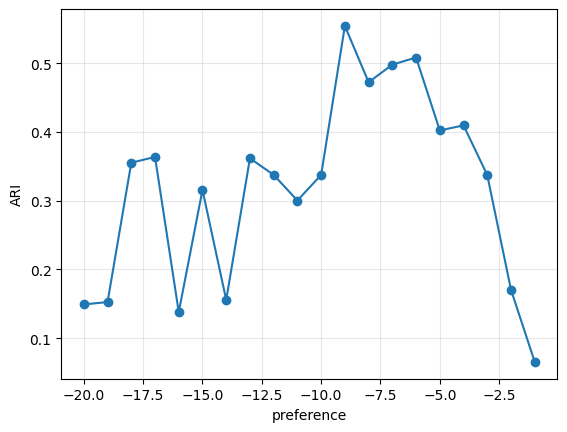

In [186]:
plt.plot(list(preferences), aris, 'o-')
plt.xlabel('preference')
plt.ylabel('ARI')
plt.grid(alpha=0.3)
plt.show()

### Agglomerative clustering

Надо подбирать кол-во кластеров (=значений) полностью руками. `linkage` более предсказуемый: `'ward'` минимизирует дисперсию, кластеры должны получаться неразнородными внутри себя; `'complete'` -- расстояние между двумя самыми далёкими текстами групп, значит будет чувствителен к выбросам, `'average'` среднее расстояние по всем парам, `'single'` -- расстояние между двумя самыми близкими текстами групп, будет вытягивать как бы цепочки и склеивать почти всё в один большой кластер.

Построим хитмап.

ward, euclidean, n=2 | ARI: 0.813 | время: 0.03
ward, euclidean, n=3 | ARI: 0.58 | время: 0.04
ward, euclidean, n=4 | ARI: 0.434 | время: 0.03
ward, euclidean, n=5 | ARI: 0.349 | время: 0.03
ward, euclidean, n=6 | ARI: 0.326 | время: 0.04
ward, euclidean, n=7 | ARI: 0.239 | время: 0.04
ward, euclidean, n=8 | ARI: 0.219 | время: 0.05
ward, euclidean, n=9 | ARI: 0.202 | время: 0.04
ward, euclidean, n=10 | ARI: 0.18 | время: 0.03
complete, cosine, n=2 | ARI: 0.5 | время: 0.04
complete, cosine, n=3 | ARI: 0.529 | время: 0.06
complete, cosine, n=4 | ARI: 0.518 | время: 0.04
complete, cosine, n=5 | ARI: 0.425 | время: 0.04
complete, cosine, n=6 | ARI: 0.419 | время: 0.05
complete, cosine, n=7 | ARI: 0.332 | время: 0.03
complete, cosine, n=8 | ARI: 0.306 | время: 0.04
complete, cosine, n=9 | ARI: 0.272 | время: 0.11
complete, cosine, n=10 | ARI: 0.241 | время: 0.1
average, cosine, n=2 | ARI: 0.278 | время: 0.15
average, cosine, n=3 | ARI: 0.585 | время: 0.06
average, cosine, n=4 | ARI: 0.546 

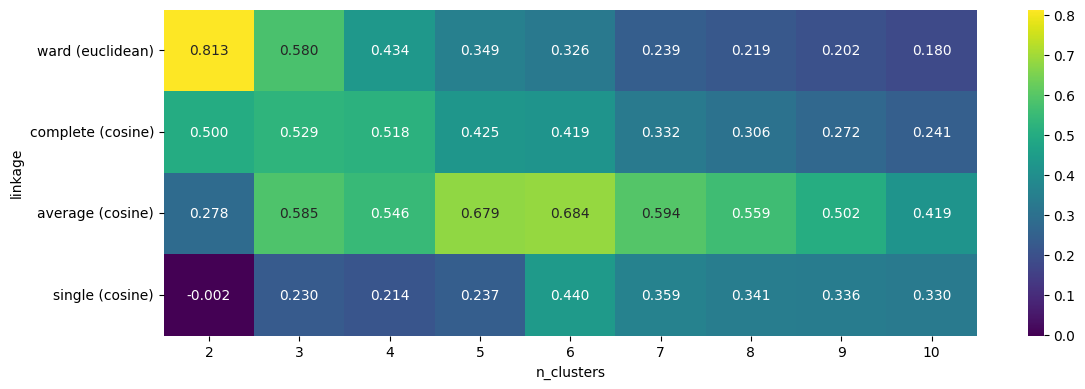

In [194]:
linkages = [
    ('ward',     'euclidean'),
    ('complete', 'cosine'),
    ('average',  'cosine'),
    ('single',   'cosine'),
]
n_clusters_list = list(range(2, 11))

results = {}
for link, metric in linkages:
    for n in n_clusters_list:
        results[(link, metric, n)] = evaluate(AgglomerativeClustering(n_clusters=n, linkage=link, metric=metric), f'{link}, {metric}, n={n}')

df = pd.DataFrame(
    [[results[(link, metric, n)] for n in n_clusters_list]
     for link, metric in linkages],
    index=[f'{l} ({m})' for l, m in linkages],
    columns=n_clusters_list
)

best_row, best_n = df.stack().idxmax()
print(f'Лучшее: {best_row}, n_clusters={best_n}, ARI={df.stack().max():.3f}')

plt.figure(figsize=(12, 4))
sns.heatmap(df, annot=True, fmt='.3f', cmap='viridis')
plt.xlabel('n_clusters')
plt.ylabel('linkage')
plt.tight_layout()
plt.show()

### Kmeans

Для хорошего результата надо заранее знать число смыслов = число кластеров.

Забавно, что KMeans n=2 (0.391) хуже, чем KMeans n=3 (0.560), хотя кластеров в golg standart -- 2! Видимо, ловушка в том, что KMeans любит равные кластеры, поэтому два кластера определяет примерно пополам, и это вызывает бОльшую ошибку. ARI больше прощает дробление,  чем слипание.

n_clusters=2 | ARI: 0.391 | время: 0.16
n_clusters=3 | ARI: 0.56 | время: 0.13
n_clusters=4 | ARI: 0.472 | время: 0.08
n_clusters=5 | ARI: 0.386 | время: 0.16
n_clusters=6 | ARI: 0.307 | время: 0.18
n_clusters=7 | ARI: 0.225 | время: 0.11
n_clusters=8 | ARI: 0.209 | время: 0.05
n_clusters=9 | ARI: 0.178 | время: 0.1
n_clusters=10 | ARI: 0.182 | время: 0.26


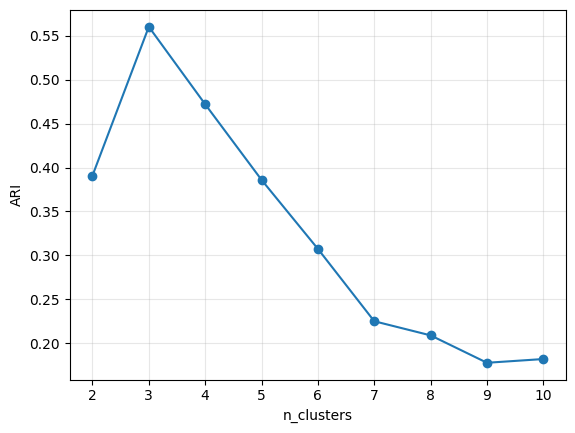

In [162]:
n_clusters_list = range(2, 11)
aris = [evaluate(KMeans(n), f'n_clusters={n}') for n in n_clusters_list]

plt.plot(n_clusters_list, aris, 'o-')
plt.xlabel('n_clusters')
plt.ylabel('ARI')
plt.grid(alpha=0.3)
plt.show()

### MeanShift

1. определить `bandwidth` -- "радиус" и точку Х (центр).
2. найти все точки A, принадлежащие сфере с таким радиусом с центром в X (но несколько сложнее, потому что мы в многомерном пространстве)
3. посчитать Х' -- центроид -- т.е. среднее всех координат A, среднюю точку.
4. заменить Х на X', повторять, пока точка X не перестанет смещаться.


Точка сдвигается туда, где вокруг неё плотнее всего.

Дефолтно иксов столько, сколько и точек A, и стартуют они с тех же мест (точки A при этом не двигаются -- относительно них иксы считают свою новую позицию). Принадлежащими одному кластеру объявляются такие Х (точнее, их предшественники А), которые сместились в одно место (или примерно одно место).

bandwidth=0.1 | ARI: 0.003 | время: 4.05
bandwidth=0.2 | ARI: 0.006 | время: 2.0
bandwidth=0.30000000000000004 | ARI: 0.011 | время: 1.89
bandwidth=0.4 | ARI: 0.028 | время: 4.97
bandwidth=0.5 | ARI: 0.037 | время: 2.74
bandwidth=0.6 | ARI: 0.137 | время: 7.15
bandwidth=0.7000000000000001 | ARI: 0.299 | время: 5.21
bandwidth=0.8 | ARI: 0.351 | время: 4.73
bandwidth=0.9 | ARI: 0.144 | время: 4.43
bandwidth=1.0 | ARI: -0.003 | время: 6.04
bandwidth=1.1 | ARI: 0.0 | время: 3.55
bandwidth=1.2000000000000002 | ARI: 0.0 | время: 1.69
bandwidth=1.3000000000000003 | ARI: 0.0 | время: 1.94
bandwidth=1.4000000000000001 | ARI: 0.0 | время: 1.3
bandwidth=1.5000000000000002 | ARI: 0.0 | время: 1.22
bandwidth=1.6 | ARI: 0.0 | время: 1.18
bandwidth=1.7000000000000002 | ARI: 0.0 | время: 1.13
bandwidth=1.8000000000000003 | ARI: 0.0 | время: 1.51
bandwidth=1.9000000000000001 | ARI: 0.0 | время: 1.14
bandwidth=2.0 | ARI: 0.0 | время: 1.17
bandwidth=2.1 | ARI: 0.0 | время: 1.23
bandwidth=2.2 | ARI: 0.0 |

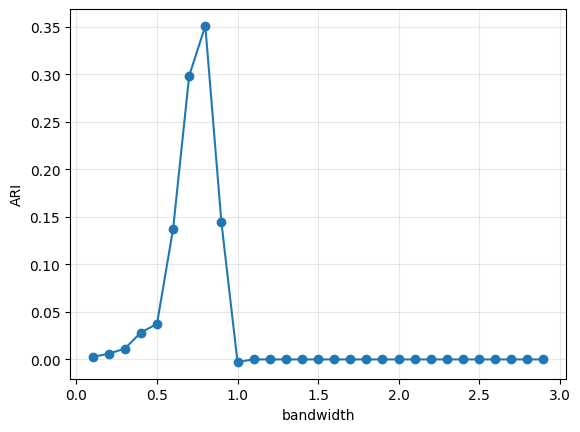

In [206]:
from sklearn.cluster import MeanShift, estimate_bandwidth

bandwidths = np.arange(0.1, 3.0, 0.1)
aris, ks = [], []
for bw in bandwidths:
    aris.append(evaluate(MeanShift(bandwidth=bw), f'bandwidth={bw}'))
    ks.append([len(set(MeanShift(bandwidth=bw).fit_predict(embeddings[w])) - {-1}) for w in embeddings])

best_i = int(np.argmax(aris))
print(f'Лучшее: bandwidth={bandwidths[best_i]:.2f}, ARI={max(aris):.3f}, кластеров по словам={ks[best_i]}')

plt.plot(bandwidths, aris, 'o-')
plt.xlabel('bandwidth')
plt.ylabel('ARI')
plt.grid(alpha=0.3)
plt.show()

### Сравнение + разбивка по словам

DBSCAN -- `Лучшее: eps=0.9, ARI=0.410, кластеров (бор, лук, замок, суда)=[2, 1, 1, 2], время 0.07`

Affinity Propagation -- `Лучшее: preference=-9, ARI=0.554, кластеров (бор, лук, замок, суда)=[2, 2, 2, 3], время 0.19`

Agglomerative clustering -- `Лучшее: ward (euclidean), n_clusters=2 для каждого слова, ARI=0.813, время 0.03`


KMeans -- `n_clusters=3 | ARI: 0.56 | время: 0.13`

MeanShift -- `Лучшее: bandwidth=0.75, ARI=0.387, кластеров [11, 13, 20, 11], время 3.07`





In [204]:
words = ['бор', 'лук', 'замок', 'суда']

best_configs = [
    ('AC', lambda: AgglomerativeClustering(n_clusters=2, linkage='ward')),
    ('KMeans', lambda: KMeans(n_clusters=3, n_init='auto', random_state=42)),
    ('AP', lambda: AffinityPropagation(preference=-9, random_state=42)),
    ('DBSCAN',  lambda: DBSCAN(eps=0.9)),
    ('MeanShift', lambda: MeanShift(bandwidth=0.75))
]

rows = []
for word in words:
    group = grouped_df.get_group(word)
    X = embeddings[word]
    y_true = group['gold_sense_id'].values

    row = {'word': word, 'n': len(X)}
    for name, make_model in best_configs:
        labels = make_model().fit_predict(X)
        row[name] = adjusted_rand_score(y_true, labels)
    rows.append(row)

df_ari = pd.DataFrame(rows).set_index('word')
df_ari.loc['среднее'] = df_ari.mean().round(3)
df_ari.round(3)

,n,AC,KMeans,AP,DBSCAN,MeanShift
word,,,,,,
бор,56.00,1.000,0.522,0.925,0.760,0.568
лук,110.00,0.893,0.643,0.728,-0.011,0.398
замок,138.00,0.911,0.526,-0.058,0.014,0.120
суда,135.00,0.448,0.623,0.623,0.875,0.462
среднее,109.75,0.813,0.578,0.554,0.410,0.387


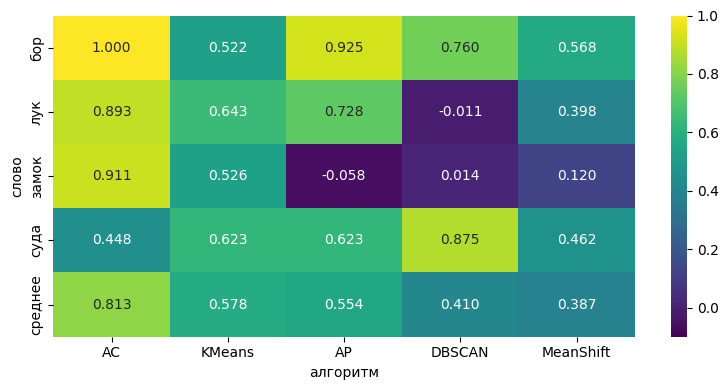

In [202]:
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.heatmap(df_ari.drop(columns='n'), annot=True, fmt='.3f', cmap='viridis', vmin=-0.1, vmax=1.0)
plt.xlabel('алгоритм')
plt.ylabel('слово')
plt.tight_layout()
plt.show()

* Agglomerative clustering плохо работает на *суда*. Это из-за плотного синего выброса (около легенды) -- алгоритм считает его отдельным кластером. AC в такой конфигурации хорошо работает с плотными кластерами (без плотных выбросов)
* KMeans работает на всех 4 словах средне, но получше на *лук* и *суда*. Но стоит помнить, что это вариант, который распределяет всё на 3 кластера. Видимо, то, что ARI оценил *лук* и *суда* выше, объясняется тем, что остальные слова имеют более неравномерные по числу кластеры.
* Affinity Propagation ужасно справился с *замок* и отлично с *бор*. В замке, видимо, его запутало пересечение облаков -- область между кластерами размытая.
* DBSCAN в целом справился плохо, хуже всех, но особенно плохо на *лук* и *замок*. Это кластеры не сильно отделенные друг от друга, и это мешает алгоритму.  


Вывод: Affinity Propagation и DBSCAN больше подходят для изолированных друг от друга кластеров. На таких данных они дают отличный результат. При этом, видимо, DBSCAN более устойчив в мини-подкластерам-выбросам, как у *суда*.

Кластеры, перетекающие друг в друга, лучше кластеризуются Agglomerative clustering.

MeanShift самый слабый. Проклятие размерности?

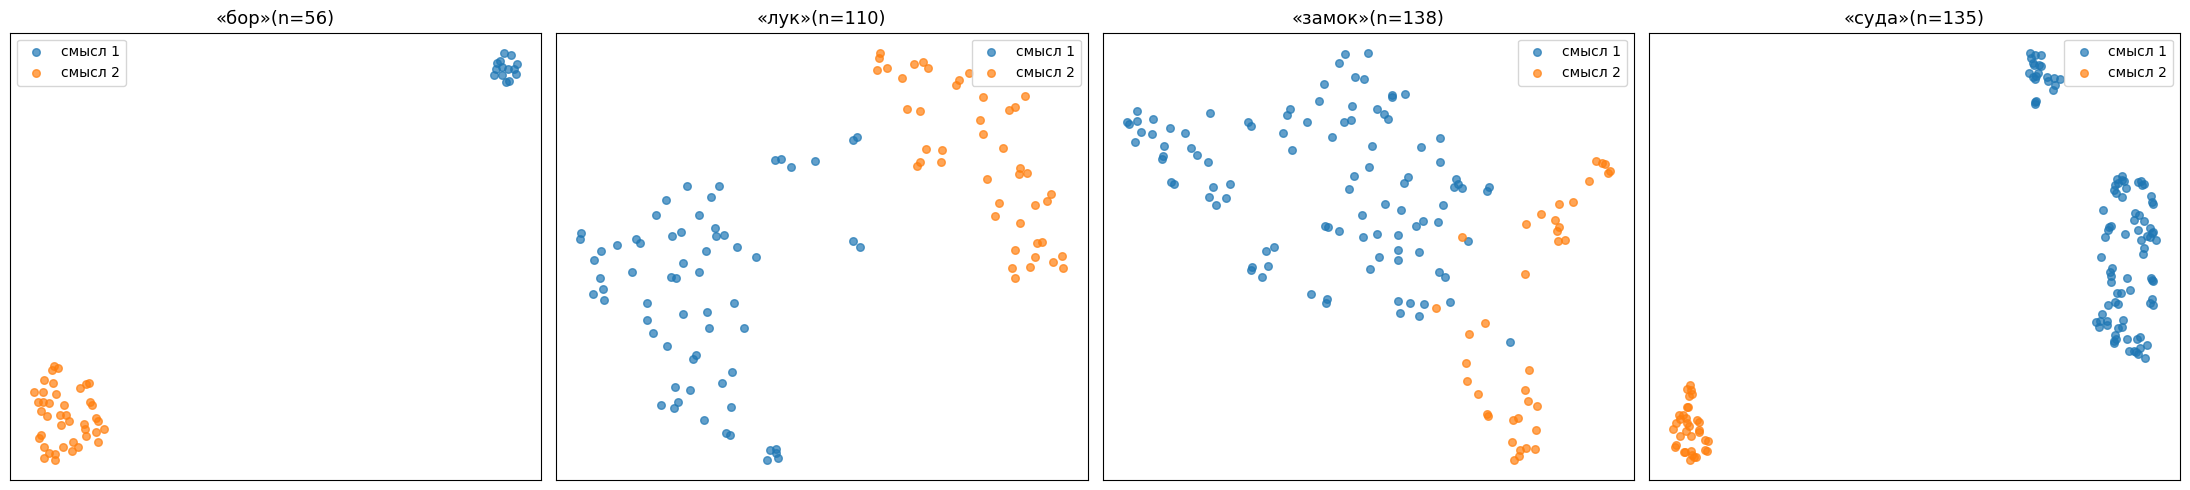

### Проклятие размерности?

Да! MeanShift плохо работает в много-многомерном пространстве.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


bw=0.10 | ARI: 0.000 | k=[56, 137, 108, 133]
bw=0.20 | ARI: 0.003 | k=[56, 123, 98, 112]
bw=0.30 | ARI: 0.015 | k=[51, 81, 71, 50]
bw=0.40 | ARI: 0.043 | k=[34, 46, 32, 27]
bw=0.50 | ARI: 0.077 | k=[16, 30, 21, 21]
bw=0.60 | ARI: 0.124 | k=[10, 20, 14, 15]
bw=0.70 | ARI: 0.156 | k=[10, 16, 11, 11]
bw=0.80 | ARI: 0.197 | k=[7, 12, 9, 9]
bw=0.90 | ARI: 0.249 | k=[6, 9, 7, 6]
bw=1.00 | ARI: 0.298 | k=[4, 8, 5, 7]
bw=1.10 | ARI: 0.320 | k=[4, 6, 5, 6]
bw=1.20 | ARI: 0.343 | k=[4, 5, 5, 6]
bw=1.30 | ARI: 0.394 | k=[3, 5, 5, 5]
bw=1.40 | ARI: 0.558 | k=[2, 4, 5, 4]
bw=1.50 | ARI: 0.619 | k=[2, 4, 4, 4]
bw=1.60 | ARI: 0.664 | k=[2, 4, 2, 4]
bw=1.70 | ARI: 0.716 | k=[2, 4, 3, 3]
bw=1.80 | ARI: 0.735 | k=[2, 3, 2, 3]
bw=1.90 | ARI: 0.730 | k=[2, 3, 2, 3]
bw=2.00 | ARI: 0.615 | k=[2, 2, 2, 3]
bw=2.10 | ARI: 0.615 | k=[2, 2, 2, 3]
bw=2.20 | ARI: 0.623 | k=[2, 1, 2, 3]
bw=2.30 | ARI: 0.623 | k=[2, 1, 2, 3]
bw=2.40 | ARI: 0.623 | k=[2, 1, 2, 3]
bw=2.50 | ARI: 0.623 | k=[2, 1, 2, 3]
bw=2.60 | ARI: 0

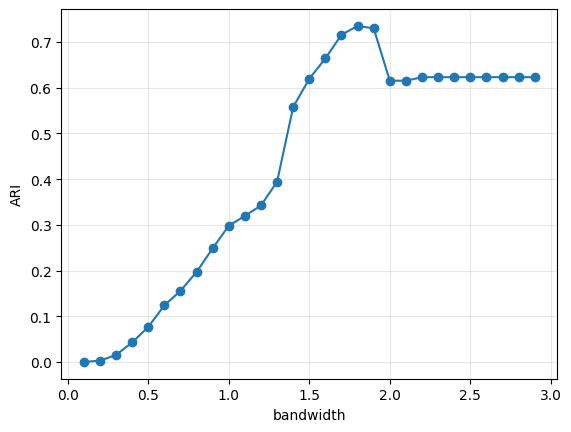

In [210]:
embeddings_50d = {w: umap.UMAP(n_components=50, random_state=42).fit_transform(embeddings[w]) for w in embeddings}

bandwidths = np.arange(0.1, 3.0, 0.1)
aris, ks = [], []
for bw in bandwidths:
    per_word_ari = []
    per_word_k = []
    for w, group in grouped_df:
        labels = MeanShift(bandwidth=bw).fit_predict(embeddings_50d[w])
        per_word_ari.append(adjusted_rand_score(group['gold_sense_id'], labels))
        per_word_k.append(len(set(labels)))
    aris.append(np.mean(per_word_ari))
    ks.append(per_word_k)
    print(f'bw={bw:.2f} | ARI: {np.mean(per_word_ari):.3f} | k={per_word_k}')

best_i = int(np.argmax(aris))
print(f'Лучшее: bandwidth={bandwidths[best_i]:.2f}, ARI={max(aris):.3f}, кластеров={ks[best_i]}')

plt.plot(bandwidths, aris, 'o-')
plt.xlabel('bandwidth'); plt.ylabel('ARI'); plt.grid(alpha=0.3); plt.show()